In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [3]:
DATA_PATH = "../data/raw/student_mental_health.csv"

df = pd.read_csv(DATA_PATH)
print("Data loaded successfully")

Data loaded successfully


In [4]:
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [6]:
list(df.columns)

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [7]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_table = missing_table[missing_table["missing"] > 0].sort_values("missing", ascending=False)
missing_table

,missing,percent
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated Student_IDs:", df["Student_ID"].duplicated().sum())

Fully duplicated rows: 0
Duplicated Student_IDs: 0


In [9]:
text_cols = df.select_dtypes(exclude="number").columns.drop("Student_ID")

for col in text_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Gender ---
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

--- Physical_Activity ---
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

--- Part_Time_Job ---
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

--- Diet_Quality ---
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

--- Previous_Mental_Health_History ---
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

--- Mental_Health_Risk ---
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64



In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.13,2.14,17.0,20.00,21.00,23.00,29.00
Year_of_Study,2000.0,2.63,1.32,1.0,1.00,2.00,4.00,5.00
Sleep_Hours,1938.0,6.76,1.13,3.3,6.00,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,20.00,5.72,2.4,16.00,19.80,24.00,38.30
GPA,1962.0,2.56,0.34,1.5,2.32,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.01,1.15,2.1,5.22,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.55,1.66,3.3,7.40,8.50,9.70,14.00
Financial_Stress,1909.0,5.96,1.89,1.4,4.50,6.10,7.40,10.00
Family_Support,1946.0,6.52,1.84,1.7,5.10,6.70,8.00,9.90
Attendance_Rate,1953.0,85.08,7.22,54.4,80.30,85.10,90.00,100.00


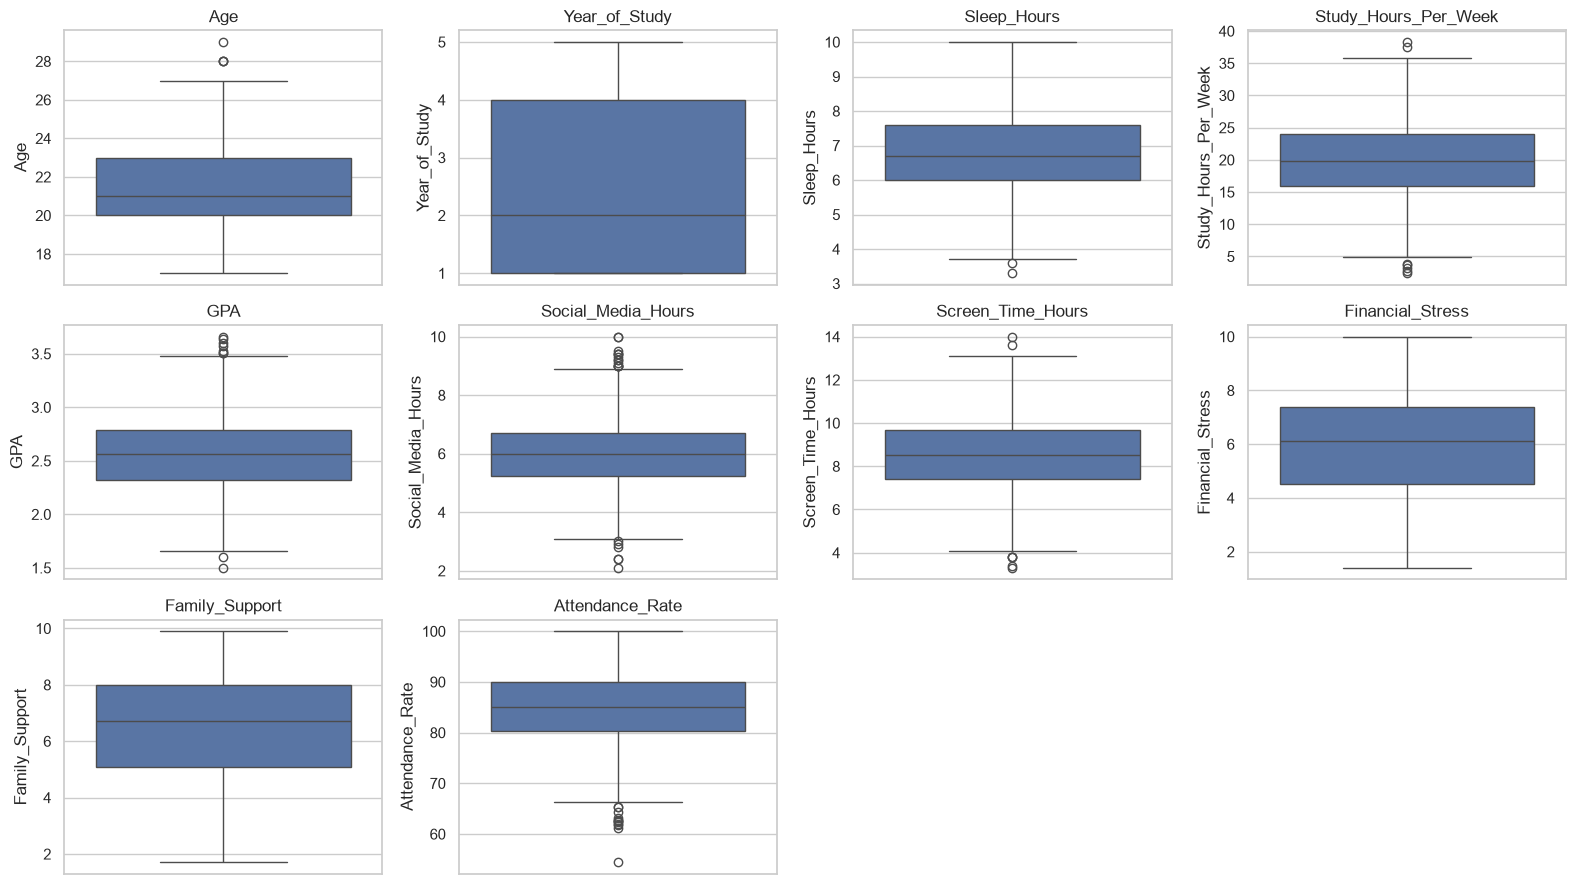

In [ ]:
num_cols = df.select_dtypes(include="number").columns

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Hide unused subplots
for j in range(len(num_cols)a len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

Mental_Health_Risk
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64


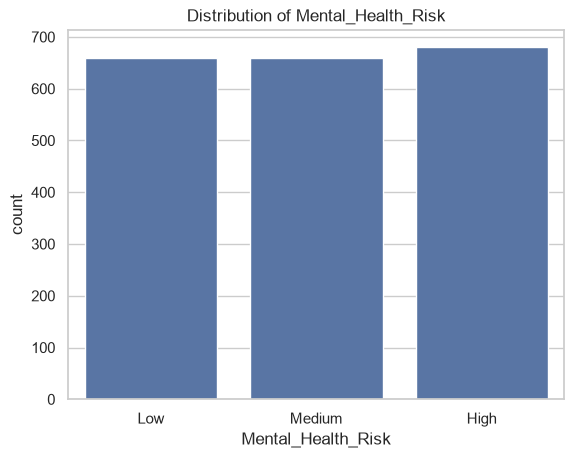

In [12]:
print(df["Mental_Health_Risk"].value_counts())
print()
print(df["Mental_Health_Risk"].value_counts(normalize=True).round(3))

order = ["Low", "Medium", "High"]
sns.countplot(data=df, x="Mental_Health_Risk", order=order)
plt.title("Distribution of Mental_Health_Risk")
plt.show()

In [13]:
num_features = [
    "Age", "Year_of_Study", "Sleep_Hours", "Study_Hours_Per_Week", "GPA",
    "Social_Media_Hours", "Screen_Time_Hours", "Financial_Stress",
    "Family_Support", "Attendance_Rate",
]

means = df.groupby("Mental_Health_Risk")[num_features].mean().loc[order].round(2)
print(means.T.to_string())

Mental_Health_Risk      Low  Medium   High
Age                   21.11   21.14  21.14
Year_of_Study          2.90    2.64   2.36
Sleep_Hours            7.52    6.73   6.04
Study_Hours_Per_Week  21.70   19.98  18.36
GPA                    2.72    2.55   2.42
Social_Media_Hours     5.76    5.92   6.35
Screen_Time_Hours      8.26    8.42   8.96
Financial_Stress       5.24    5.90   6.69
Family_Support         7.09    6.53   5.96
Attendance_Rate       86.33   85.19  83.77


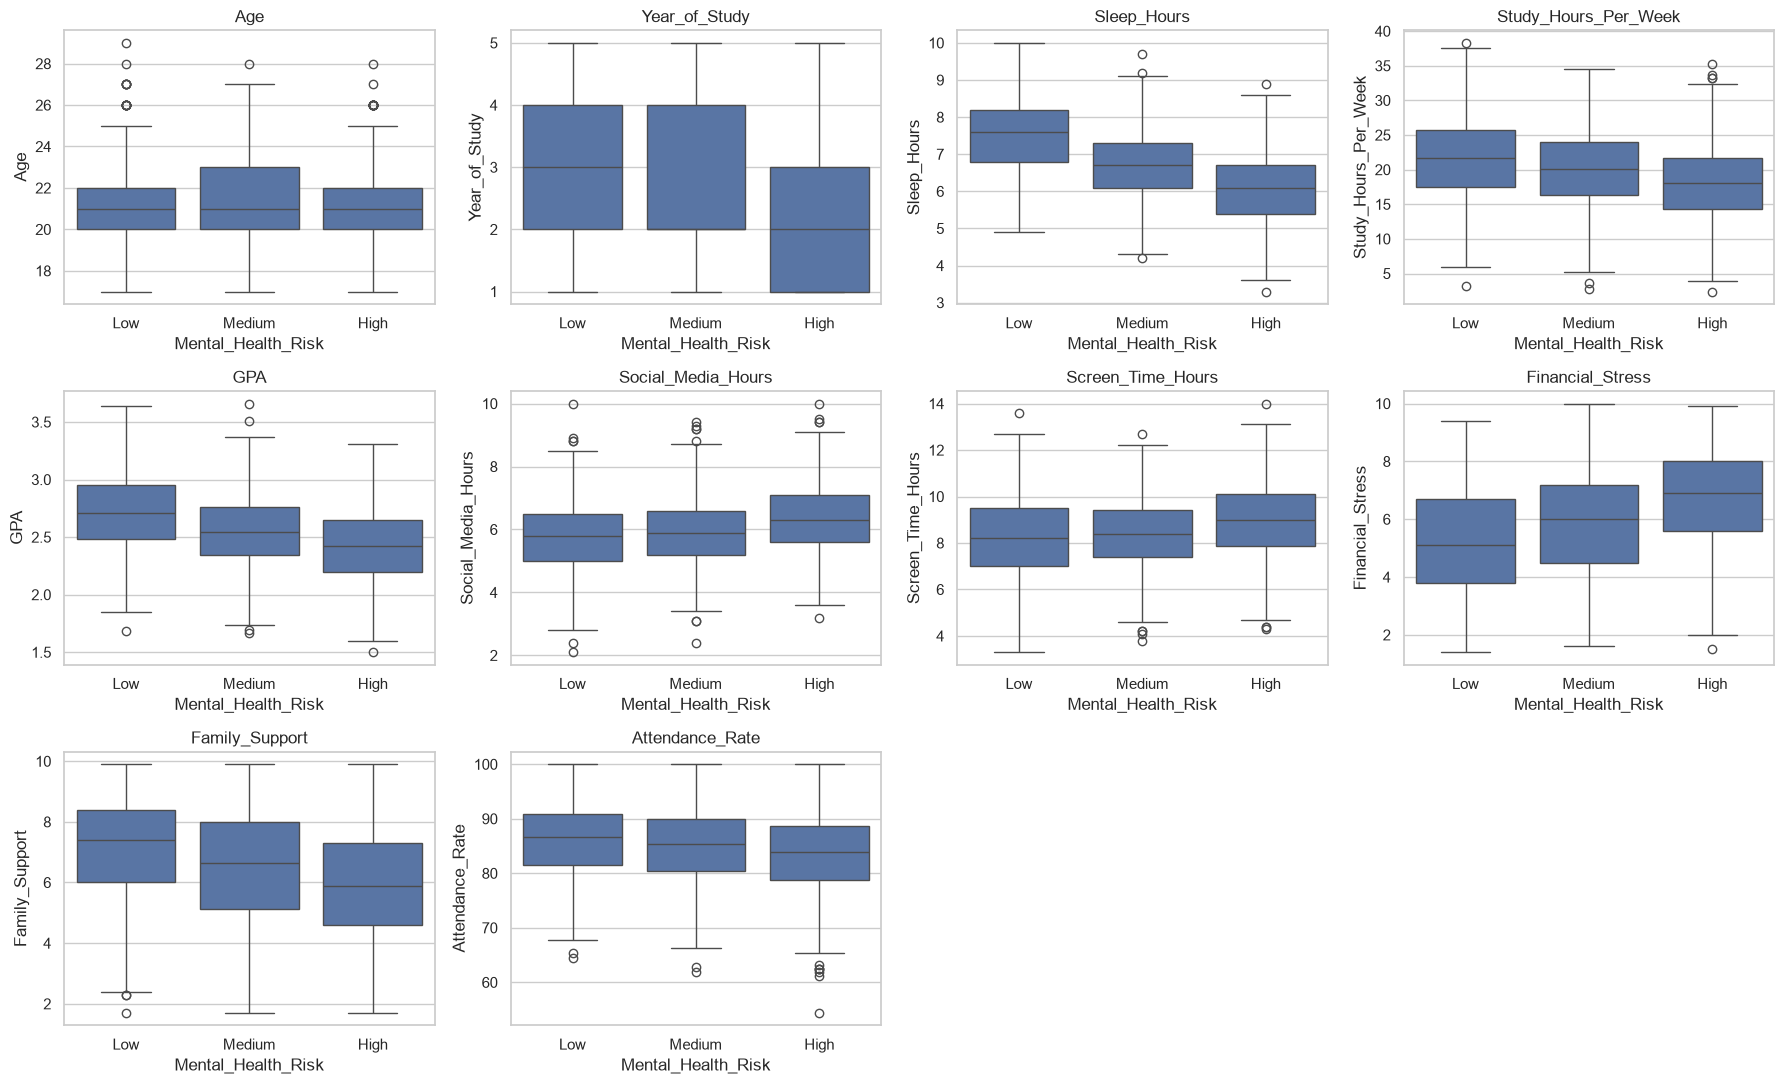

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col, order=order, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(num_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
# Each row shows the percentage of students at each risk level within a category.

cat_features = ["Gender", "Physical_Activity", "Part_Time_Job", "Diet_Quality",
                "Previous_Mental_Health_History"]

for col in cat_features:
    table = pd.crosstab(df[col], df["Mental_Health_Risk"], normalize="index")[order]
    print(f"--- {col} ---")
    print((table * 100).round(1).to_string())
    print()

--- Gender ---
Mental_Health_Risk   Low  Medium  High
Gender                                
Female              33.5    31.9  34.6
Male                31.8    34.9  33.4
Non-binary          40.2    25.8  34.0

--- Physical_Activity ---
Mental_Health_Risk   Low  Medium  High
Physical_Activity                     
High                49.4    30.4  20.2
Low                 22.8    31.2  45.9
Moderate            33.1    35.5  31.3

--- Part_Time_Job ---
Mental_Health_Risk   Low  Medium  High
Part_Time_Job                         
No                  36.2    33.5  30.3
Yes                 27.1    32.1  40.8

--- Diet_Quality ---
Mental_Health_Risk   Low  Medium  High
Diet_Quality                          
Average             33.5    34.2  32.3
Good                42.8    29.8  27.5
Poor                24.0    33.7  42.2

--- Previous_Mental_Health_History ---
Mental_Health_Risk               Low  Medium  High
Previous_Mental_Health_History                    
No                            

In [16]:
df_corr = df.copy()
df_corr["risk_num"] = df_corr["Mental_Health_Risk"].map({"Low": 0, "Medium": 1, "High": 2})

corr_with_target = df_corr[num_features + ["risk_num"]].corr()["risk_num"].drop("risk_num")
print(corr_with_target.sort_values(key=abs, ascending=False).round(3).to_string())

Sleep_Hours            -0.542
GPA                    -0.353
Financial_Stress        0.314
Family_Support         -0.251
Study_Hours_Per_Week   -0.239
Social_Media_Hours      0.208
Screen_Time_Hours       0.174
Year_of_Study          -0.166
Attendance_Rate        -0.145
Age                     0.005


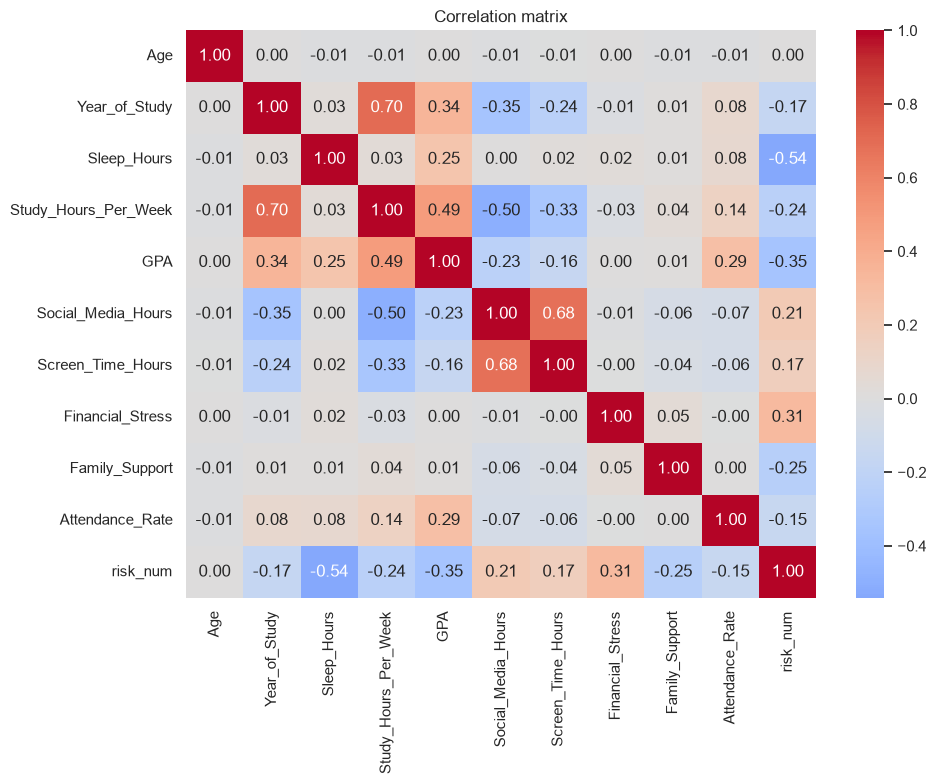

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr[num_features + ["risk_num"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()